# Task 2: California Housing Price Prediction (OLS vs Ridge vs Lasso)

**Goal:** predict `median_house_value`, engineer interaction features, impute missing values, handle multicollinearity, and compare OLS, Ridge (L2) and Lasso (L1) using RMSE, MAE and R².

**Dataset:** `housing.csv` (Aurelien Geron, Hands-On ML 2). Place it next to this notebook, or the notebook will download it.

## 1. Imports and settings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv("housing.csv") if os.path.exists("housing.csv") else pd.read_csv(URL)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Explore the data and missing values

In [3]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_va

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


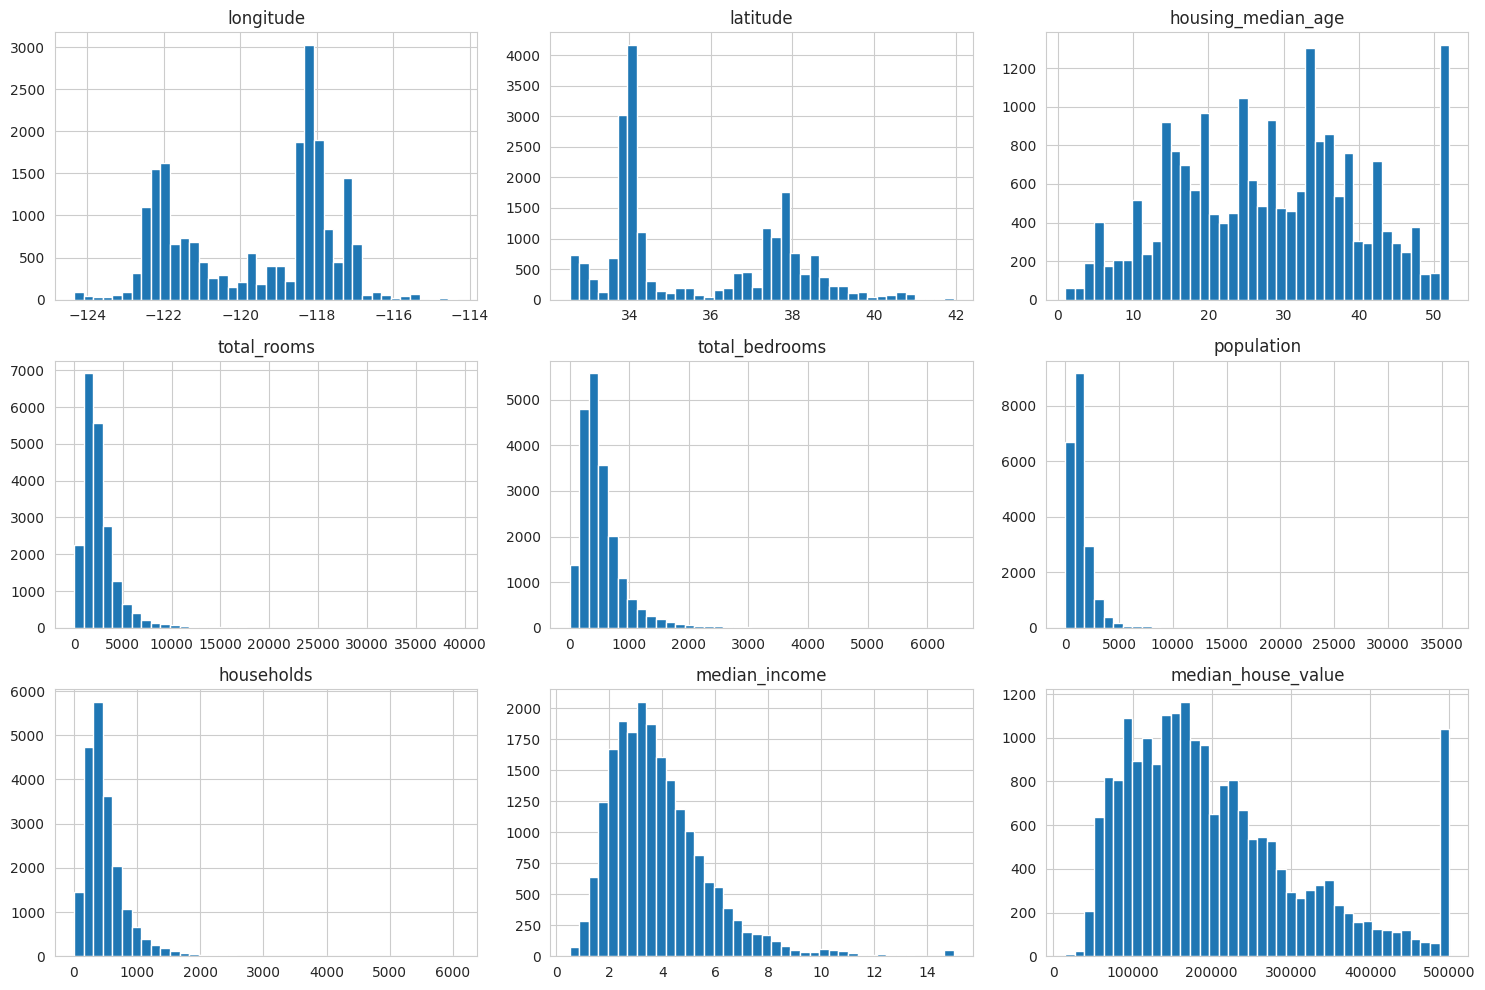

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [4]:
df.hist(bins=40, figsize=(15, 10))
plt.tight_layout()
plt.show()

print(df["ocean_proximity"].value_counts())

Notes: `total_bedrooms` has missing values (handled by median imputation inside the pipeline), and `median_house_value` is capped at 500,001, which will show up as a band in the residual plots.

## 4. Feature engineering (ratio and interaction features)

Raw counts like `total_rooms`, `total_bedrooms`, `population`, `households` are strongly correlated with each other. Per-household ratios are more meaningful and reduce multicollinearity. We also add interaction terms.

In [5]:
df_fe = df.copy()

# ratio features
df_fe["rooms_per_household"] = df_fe["total_rooms"] / df_fe["households"]
df_fe["bedrooms_per_room"] = df_fe["total_bedrooms"] / df_fe["total_rooms"]
df_fe["population_per_household"] = df_fe["population"] / df_fe["households"]

# interaction features
df_fe["income_x_rooms_per_hh"] = df_fe["median_income"] * df_fe["rooms_per_household"]
df_fe["income_x_house_age"] = df_fe["median_income"] * df_fe["housing_median_age"]
df_fe["lat_x_long"] = df_fe["latitude"] * df_fe["longitude"]

df_fe.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms_per_hh,income_x_house_age,lat_x_long
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,58.144254,341.3332,-4630.0724
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,51.785271,174.3294,-4627.2492
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,60.150315,377.3848,-4626.7840
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,32.827897,293.4412,-4627.1625
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,24.161264,200.0024,-4627.1625


## 5. Correlation heatmaps (multicollinearity check)

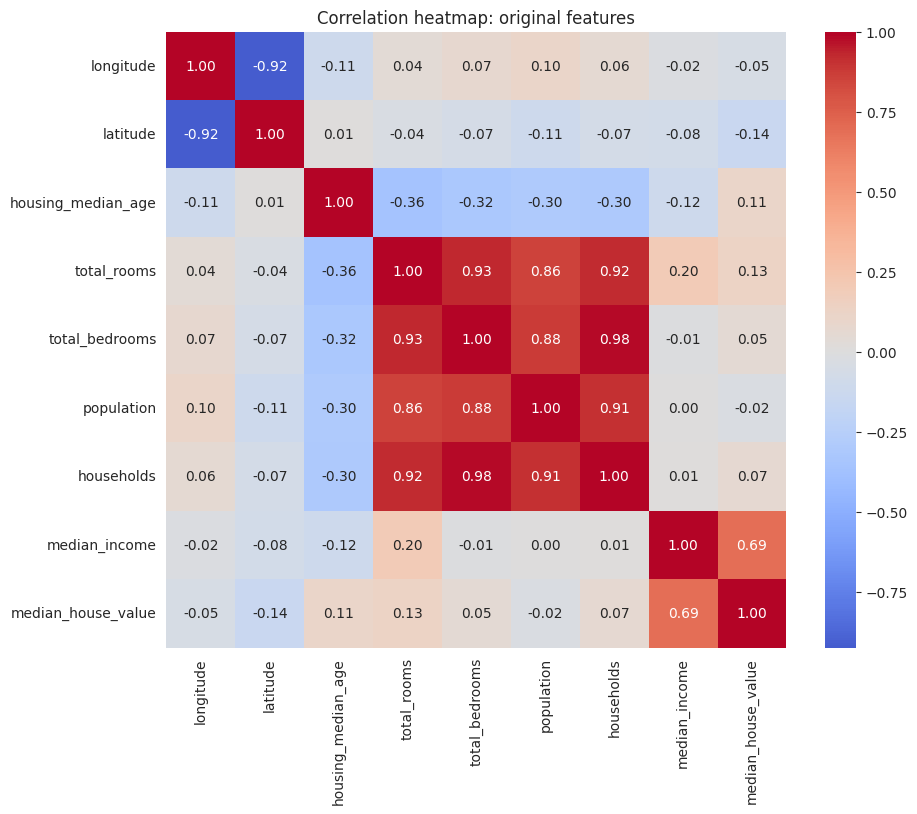

In [6]:
num_raw = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 8))
sns.heatmap(num_raw.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap: original features")
plt.show()

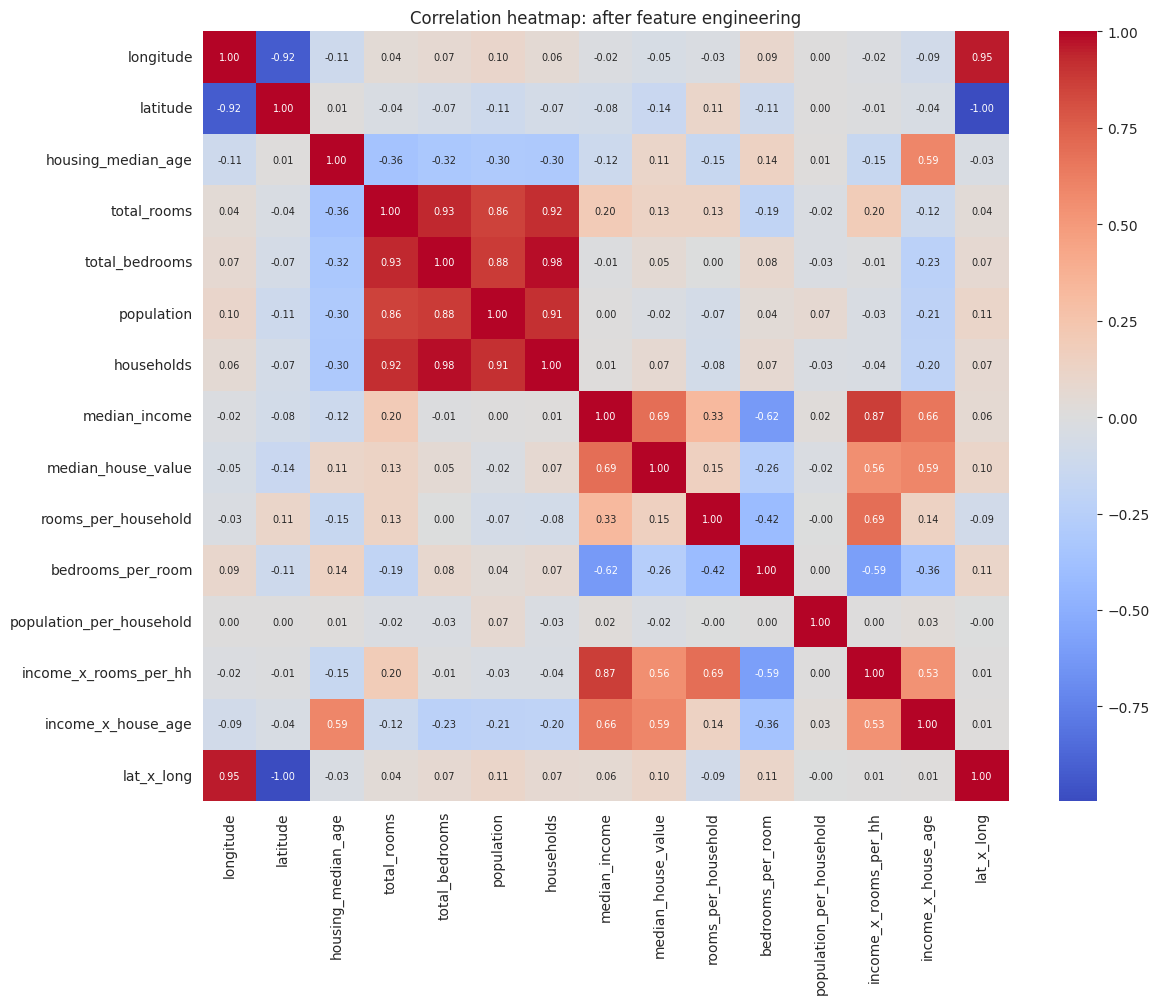

median_house_value          1.000000
median_income               0.688075
income_x_house_age          0.589142
income_x_rooms_per_hh       0.555438
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
lat_x_long                  0.104524
households                  0.065843
total_bedrooms              0.049686
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64


In [7]:
num_fe = df_fe.select_dtypes(include=np.number)
plt.figure(figsize=(13, 10))
sns.heatmap(num_fe.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap: after feature engineering")
plt.show()

# strongest correlations with the target
print(num_fe.corr()["median_house_value"].sort_values(ascending=False))

In [8]:
# Optional: Variance Inflation Factor (needs statsmodels). Skipped automatically if not installed.
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    X_vif = num_raw.drop(columns="median_house_value").fillna(num_raw.median())
    vif = pd.DataFrame({
        "feature": X_vif.columns,
        "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    }).sort_values("VIF", ascending=False)
    display(vif)
except ImportError:
    print("statsmodels not installed - skipping VIF (heatmap is enough).")

,feature,VIF
6,households,28.284141
4,total_bedrooms,26.882085
3,total_rooms,12.126382
1,latitude,8.826607
0,longitude,8.703623
5,population,6.261680
7,median_income,1.688920
2,housing_median_age,1.259064


## 6. Train/test split and preprocessing pipeline

Imputation and scaling are inside a `Pipeline`, so they are fit only on training folds (no data leakage during cross-validation).

In [9]:
X = df_fe.drop(columns="median_house_value")
y = df_fe["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = ["ocean_proximity"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (16512, 15)  Test: (4128, 15)


## 7. Fit the models

In [10]:
# --- OLS baseline ---
ols = Pipeline([("prep", preprocess), ("model", LinearRegression())])
ols.fit(X_train, y_train)

# --- Ridge with GridSearchCV ---
ridge_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Ridge())]),
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_)

# --- Lasso with GridSearchCV ---
lasso_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Lasso(max_iter=20000))]),
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 500, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
lasso_grid.fit(X_train, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_)

Best Ridge alpha: {'model__alpha': 0.001}
Best Lasso alpha: {'model__alpha': 0.01}


## 8. Evaluation: RMSE, MAE, R²

In [11]:
models = {
    "OLS": ols,
    "Ridge (L2)": ridge_grid.best_estimator_,
    "Lasso (L1)": lasso_grid.best_estimator_,
}

rows, preds = [], {}
for name, m in models.items():
    for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        p = m.predict(Xs)
        if split == "Test":
            preds[name] = p
        rows.append({
            "Model": name, "Split": split,
            "RMSE": np.sqrt(mean_squared_error(ys, p)),
            "MAE": mean_absolute_error(ys, p),
            "R2": r2_score(ys, p),
        })

results = pd.DataFrame(rows)
results.round(4)

,Model,Split,RMSE,MAE,R2
0,OLS,Train,67132.1539,48386.1882,0.6629
1,OLS,Test,68528.4137,49164.3245,0.6416
2,Ridge (L2),Train,67132.1546,48386.1282,0.6629
3,Ridge (L2),Test,68528.5648,49164.4659,0.6416
4,Lasso (L1),Train,67147.1617,48391.7110,0.6627
5,Lasso (L1),Test,68564.7325,49203.9798,0.6412


,RMSE,MAE,R2
Model,,,
OLS,68528.4137,49164.3245,0.6416
Ridge (L2),68528.5648,49164.4659,0.6416
Lasso (L1),68564.7325,49203.9798,0.6412


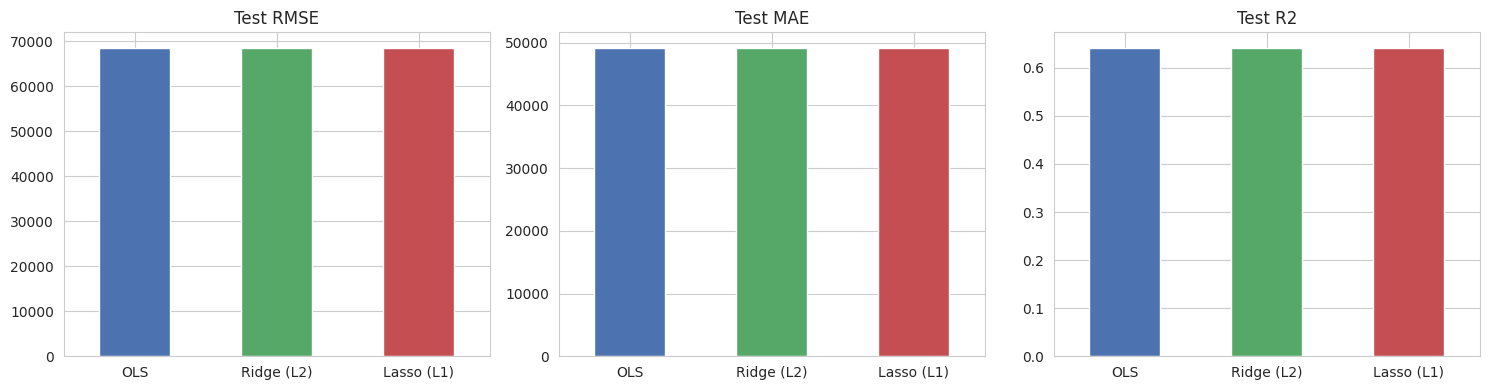

In [12]:
test_results = results[results["Split"] == "Test"].set_index("Model")[["RMSE", "MAE", "R2"]]
display(test_results.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, metric in zip(ax, ["RMSE", "MAE", "R2"]):
    test_results[metric].plot(kind="bar", ax=a, color=["#4C72B0", "#55A868", "#C44E52"])
    a.set_title(f"Test {metric}")
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 9. Predicted vs actual

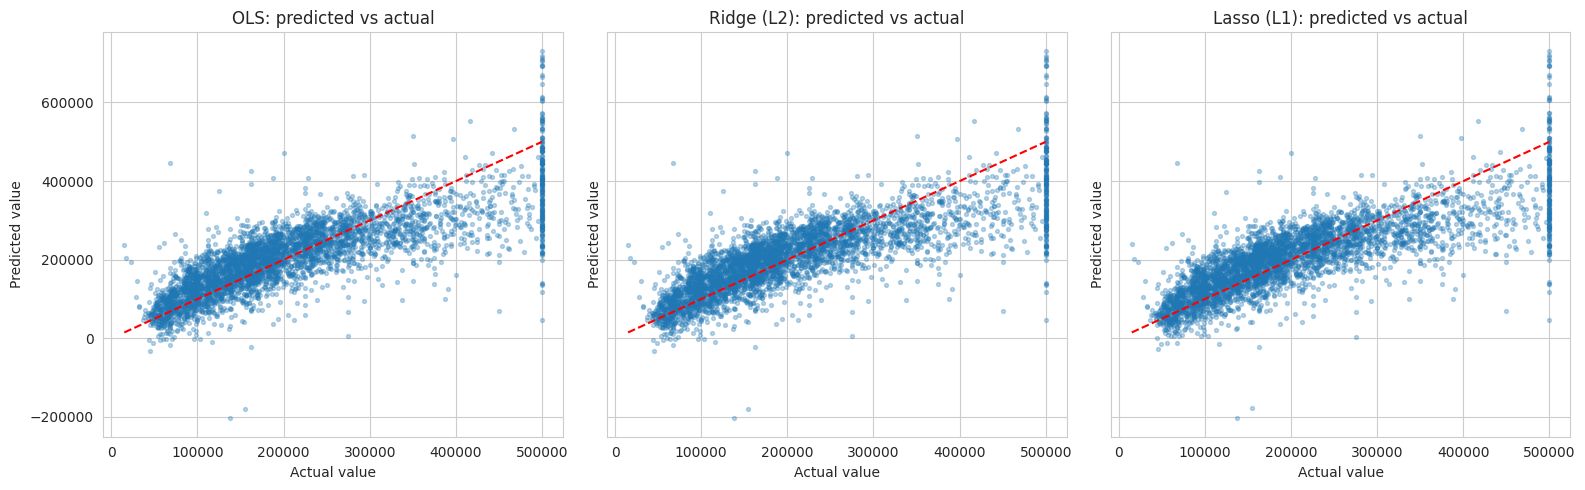

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.3, s=8)
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.set_title(f"{name}: predicted vs actual")
    ax.set_xlabel("Actual value")
    ax.set_ylabel("Predicted value")
plt.tight_layout()
plt.show()

## 10. Residual error analysis

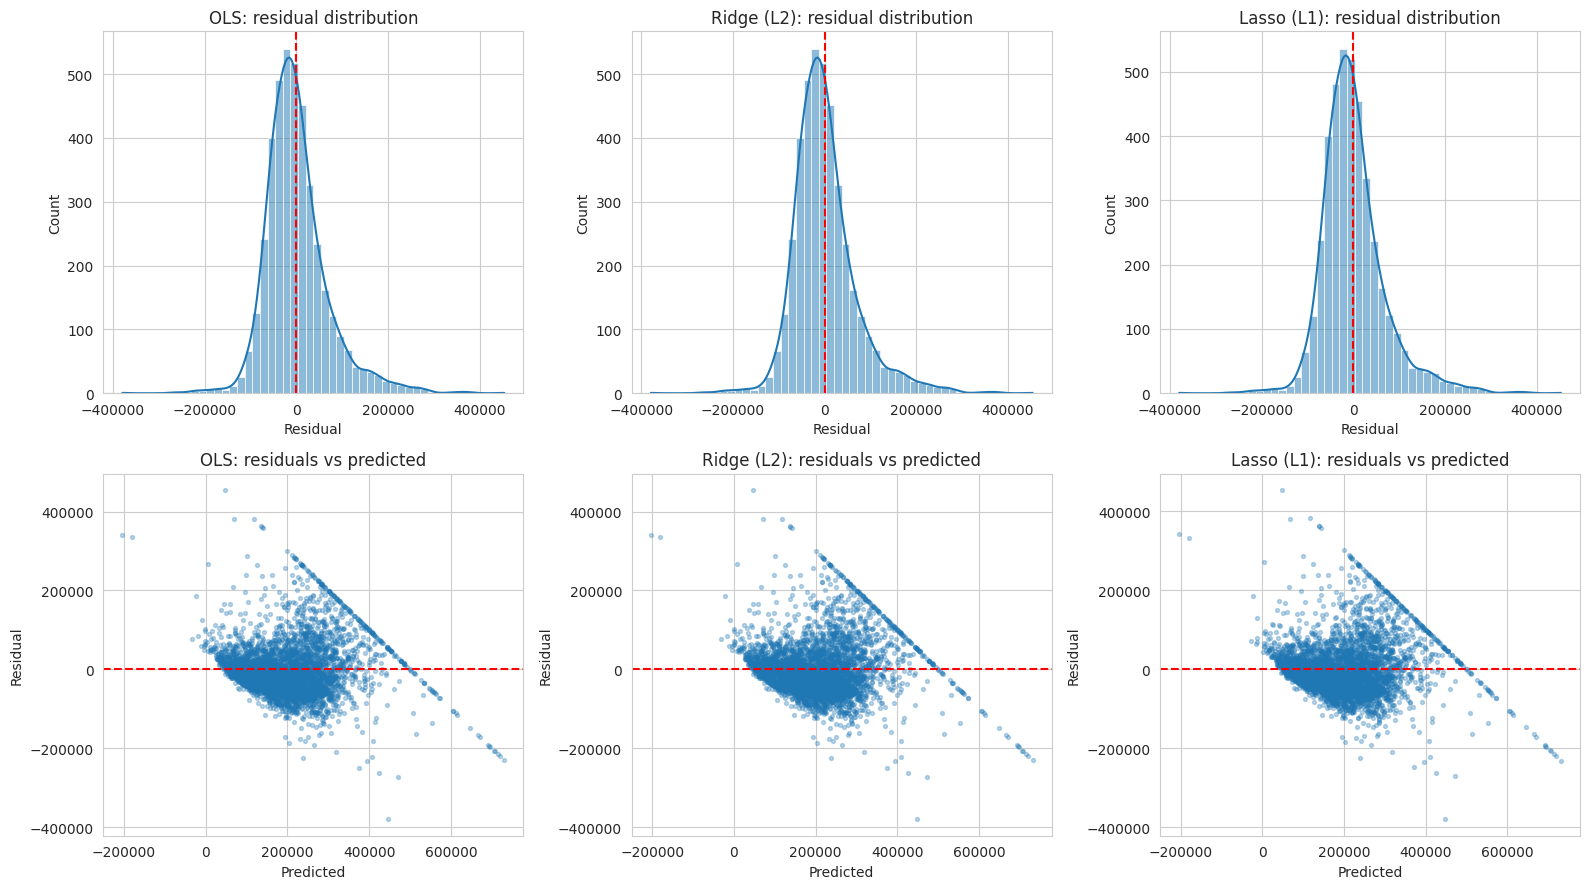

OLS          mean residual =     753.36   std =   68532.57
Ridge (L2)   mean residual =     753.44   std =   68532.72
Lasso (L1)   mean residual =     765.07   std =   68568.77


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, (name, p) in enumerate(preds.items()):
    resid = y_test - p
    sns.histplot(resid, kde=True, bins=50, ax=axes[0, i])
    axes[0, i].axvline(0, color="r", ls="--")
    axes[0, i].set_title(f"{name}: residual distribution")
    axes[0, i].set_xlabel("Residual")

    axes[1, i].scatter(p, resid, alpha=0.3, s=8)
    axes[1, i].axhline(0, color="r", ls="--")
    axes[1, i].set_title(f"{name}: residuals vs predicted")
    axes[1, i].set_xlabel("Predicted")
    axes[1, i].set_ylabel("Residual")
plt.tight_layout()
plt.show()

for name, p in preds.items():
    r = y_test - p
    print(f"{name:12s} mean residual = {r.mean():10.2f}   std = {r.std():10.2f}")

## 11. Coefficients: effect of regularization and multicollinearity

,OLS,Ridge,Lasso
longitude,-208390.48,-208135.31,-170130.71
latitude,530281.21,529293.36,381575.14
housing_median_age,5513.66,5514.52,5640.50
total_rooms,11618.42,11616.92,11394.56
total_bedrooms,2691.41,2691.92,2759.14
population,-45968.04,-45967.12,-45834.99
households,36973.27,36973.37,36999.12
median_income,80111.48,80113.28,80386.26
rooms_per_household,12620.03,12621.43,12838.41
bedrooms_per_room,18108.78,18109.85,18272.50


Features zeroed out by Lasso: []


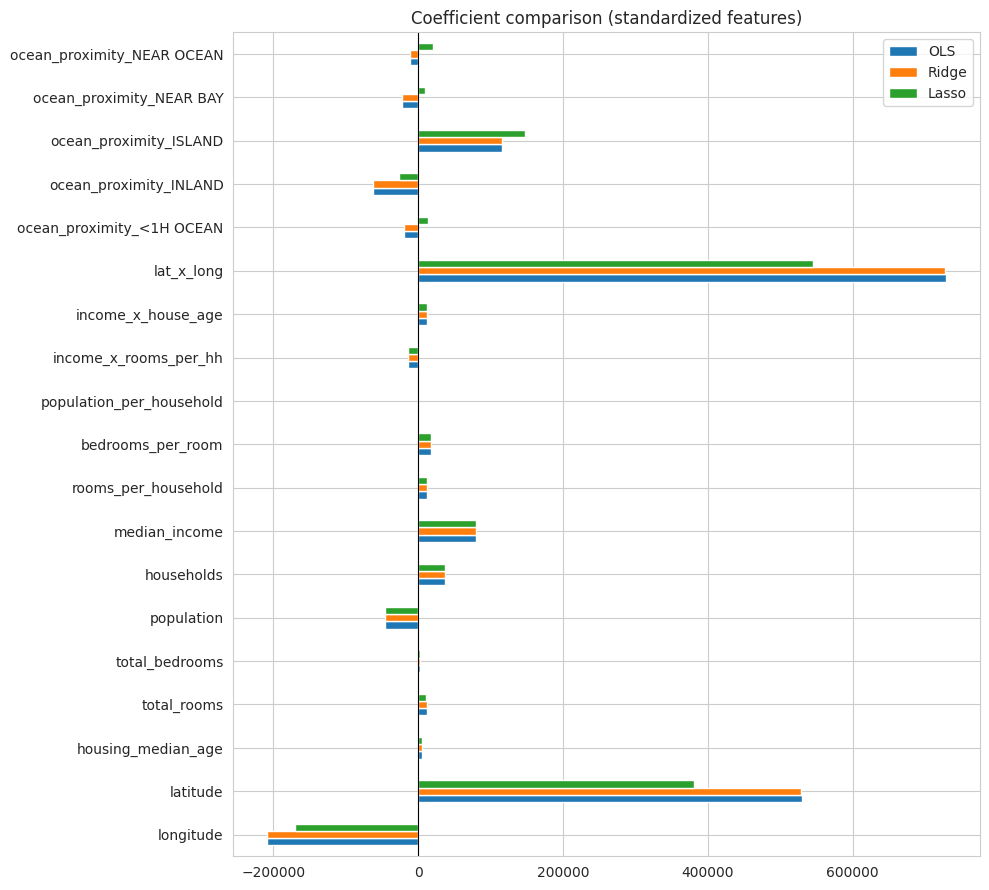

In [15]:
feature_names = (
    num_cols
    + list(ols.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(cat_cols))
)

coef_df = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": ridge_grid.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_grid.best_estimator_.named_steps["model"].coef_,
}, index=feature_names)

display(coef_df.round(2))
print("Features zeroed out by Lasso:", list(coef_df.index[coef_df["Lasso"] == 0]))

coef_df.plot(kind="barh", figsize=(10, 9))
plt.title("Coefficient comparison (standardized features)")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.show()

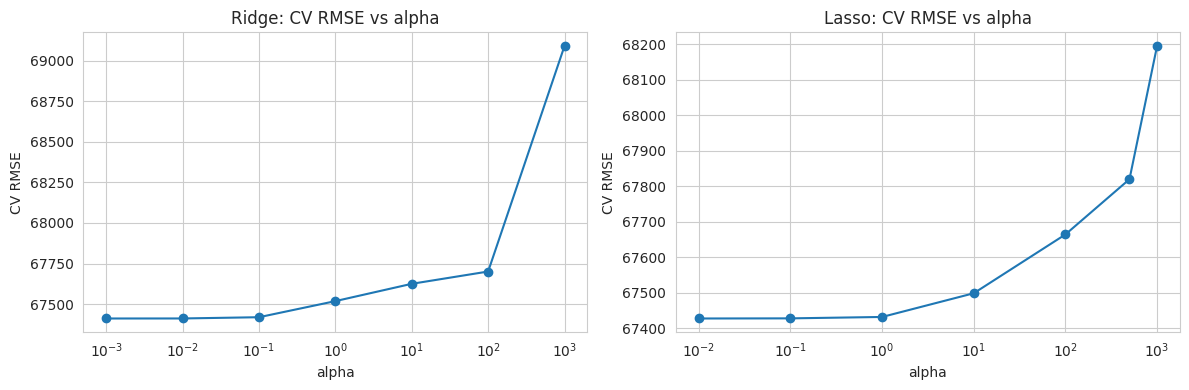

In [16]:
# Effect of alpha on Lasso/Ridge test RMSE (CV results)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, grid, title in zip(ax, [ridge_grid, lasso_grid], ["Ridge", "Lasso"]):
    cvr = pd.DataFrame(grid.cv_results_)
    a.semilogx(cvr["param_model__alpha"].astype(float), -cvr["mean_test_score"], marker="o")
    a.set_title(f"{title}: CV RMSE vs alpha")
    a.set_xlabel("alpha")
    a.set_ylabel("CV RMSE")
plt.tight_layout()
plt.show()

## 12. Conclusion

**Test-set results**

| Model | RMSE | MAE | R² |
|---|---|---|---|
| OLS | 68528.41 | 49164.32 | 0.6416 |
| Ridge (L2) | 68528.56 | 49164.47 | 0.6416 |
| Lasso (L1) | 68564.73 | 49203.98 | 0.6412 |

**Best hyperparameters (GridSearchCV, 5-fold):** Ridge alpha = 'model__alpha': 0.001, Lasso alpha = 'model__alpha': 0.01.

**Observations**
- All three models perform almost identically. OLS has the lowest test RMSE (68528.41), with Ridge essentially tied and Lasso slightly worse. The differences are far too small to matter in practice.
- Train and test scores are close (R² of about 0.663 vs 0.642), so there is no overfitting. This is why regularization gives no real gain: OLS is not overfitting, so shrinking the coefficients has little to fix.
- Multicollinearity was reduced mainly through feature engineering (per-household ratios replaced highly correlated raw counts such as total_rooms, total_bedrooms, population and households). Ridge shrinks the remaining correlated coefficients slightly, which makes them more stable.
- Lasso removed the following features (coefficient = 0). (If the list is empty, write "Lasso did not remove any feature, because the chosen alpha was small.")
- An R² of about 0.64 means the models explain roughly 64% of the variance in house prices. The remaining error suggests the relationship is non-linear.
- Residual plots show a band caused by the capped target value (500,001) and larger errors for expensive houses, so the linear models underpredict high-priced homes and the errors are not perfectly constant.

**Possible improvements:** log-transform the target, add polynomial or geospatial features (for example distance to the coast or to major cities), or use non-linear models such as Random Forest or Gradient Boosting.